In [3]:
%load_ext autoreload
%autoreload 2
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from itertools import combinations
from scipy.optimize import minimize, minimize_scalar

In [4]:
# Output directory for plots
plots_dir = os.path.join(os.getcwd(), "plots")
os.makedirs(plots_dir, exist_ok=True)

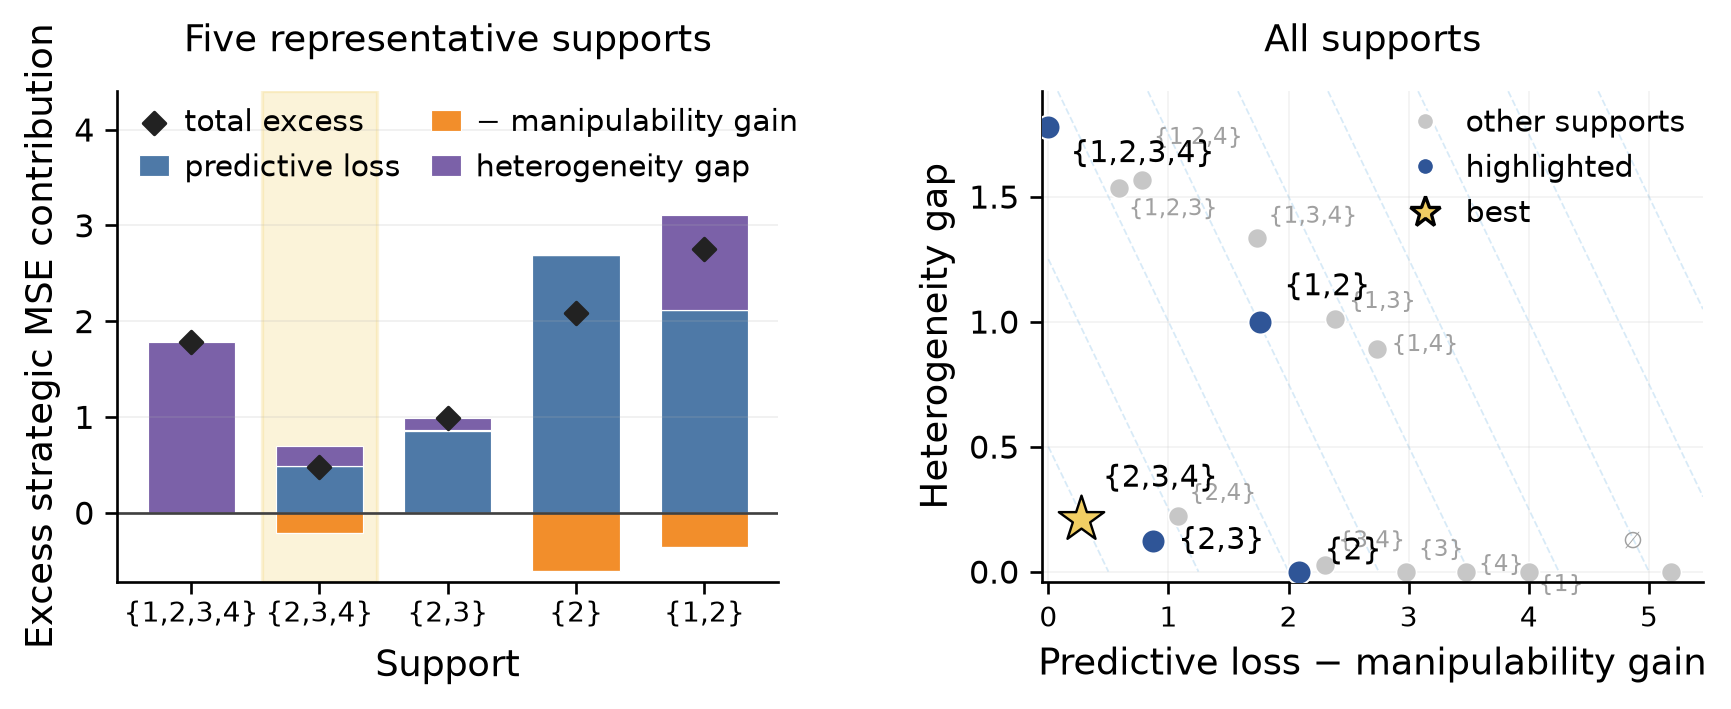

In [5]:
# Problem setup
Sigma = np.array([
    [1,   0.9, 0.2, 0.1],
    [0.9, 1,   0.2, 0.1],
    [0.2, 0.2, 1,   0.5],
    [0.1, 0.1, 0.5, 1],
], float)
theta_star = np.array([1.6, 1.2, 1.0, 0.7], float)
Hinv = np.diag([8.0, 1.5, 0.8, 0.5])
d = 4

# Core functions
def F(theta):
    diff = theta - theta_star
    return float(diff @ Sigma @ diff + (theta @ Hinv @ theta) ** 2)

def theta_ls(S):
    S = list(S)
    if not S: return np.zeros(0)
    R = [i for i in range(d) if i not in S]
    SS = Sigma[np.ix_(S, S)]
    Sy = SS @ theta_star[S]
    if R: Sy += Sigma[np.ix_(S, R)] @ theta_star[R]
    return np.linalg.solve(SS, Sy)

def opt_support(S):
    S = list(S)
    if not S:
        th = np.zeros(d)
        return F(th), th
    init = theta_ls(S)
    def obj(eta):
        th = np.zeros(d)
        th[S] = eta
        return F(th)
    def grad(eta):
        th = np.zeros(d)
        th[S] = eta
        q = th @ Hinv @ th
        return (2 * Sigma @ (th - theta_star) + 4 * q * (Hinv @ th))[S]
    res = minimize(obj, init, jac=grad, method="BFGS", options={"gtol": 1e-12})
    th = np.zeros(d)
    th[S] = res.x
    return F(th), th

def theta_or(S, lam):
    S = list(S)
    th = np.zeros(d)
    if not S: return th
    R = [i for i in range(d) if i not in S]
    SS = Sigma[np.ix_(S, S)]
    Sy = SS @ theta_star[S]
    if R: Sy += Sigma[np.ix_(S, R)] @ theta_star[R]
    th[S] = np.linalg.solve(SS + lam * np.eye(len(S)), Sy)
    return th

def ridge_best(S):
    def obj(lam): return F(theta_or(S, lam))
    res = minimize_scalar(obj, bounds=(0, 100), method="bounded", options={"xatol": 1e-12})
    cand = [(0.0, obj(0.0)), (res.x, res.fun)]
    lam, val = min(cand, key=lambda z: z[1])
    return float(val), float(lam)

def L_pred(S):
    S = list(S)
    R = [i for i in range(d) if i not in S]
    if not R: return 0.0
    if not S: return float(theta_star @ Sigma @ theta_star)
    cond = Sigma[np.ix_(R, R)] - Sigma[np.ix_(R, S)] @ np.linalg.solve(Sigma[np.ix_(S, S)], Sigma[np.ix_(S, R)])
    return float(theta_star[R] @ cond @ theta_star[R])

# Compute tradeoffs
rows = []
for k in range(d + 1):
    for S in combinations(range(d), k):
        opt, _ = opt_support(S)
        rb, lam = ridge_best(S)
        rows.append({
            "label_plain": "{}" if len(S) == 0 else "{" + ",".join(str(i + 1) for i in S) + "}",
            "size": k,
            "oracle": opt,
            "ridge_gap": rb - opt,
            "L_pred": L_pred(S),
        })
summary = pd.DataFrame(rows)
full_oracle = float(summary.loc[summary["size"] == d, "oracle"].iloc[0])
summary["Gamma"] = summary["oracle"] - summary["L_pred"]
Gamma_full = float(summary.loc[summary["size"] == d, "Gamma"].iloc[0])
summary["minus_Delta_manip"] = -(Gamma_full - summary["Gamma"])
summary["support_cost"] = summary["oracle"] - full_oracle
summary["total_excess"] = summary["support_cost"] + summary["ridge_gap"]

# Plotting setup
selected_plain = ["{1,2,3,4}", "{2,3,4}", "{2,3}", "{2}", "{1,2}"]
selected = summary.set_index("label_plain").loc[selected_plain].reset_index()

plt.rcParams.update({
    "font.size": 10.0,
    "axes.labelsize": 11.0,
    "axes.titlesize": 11.0,
    "xtick.labelsize": 8.5,
    "ytick.labelsize": 9.5,
    "legend.fontsize": 9.0,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.dpi": 240,
    "savefig.dpi": 300,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

colors = {"pred": "#4E79A7", "manip": "#F28E2B", "ridge": "#7B61A8", "total": "#222222",
          "best": "#F1CE63", "selected": "#2F5597", "other": "#C7C7C7", "other_text": "#A0A0A0", "contour": "#75B7E5"}

fig, axs = plt.subplots(1, 2, figsize=(7.55, 3.05))

# Left panel (bar chart)
ax = axs[0]
x = np.arange(len(selected))
width = 0.68
pos, neg = np.zeros(len(selected)), np.zeros(len(selected))
for col, c, lab in [("L_pred", colors["pred"], "predictive loss"),
                    ("minus_Delta_manip", colors["manip"], r"$-$ manipulability gain"),
                    ("ridge_gap", colors["ridge"], "heterogeneity gap")]:
    vals = selected[col].to_numpy(float)
    vp, vn = np.clip(vals, 0, None), np.clip(vals, None, 0)
    ax.bar(x, vp, width, bottom=pos, color=c, edgecolor="white", linewidth=0.35, label=lab)
    ax.bar(x, vn, width, bottom=neg, color=c, edgecolor="white", linewidth=0.35)
    pos += vp; neg += vn

ax.scatter(x, selected["total_excess"], marker="D", s=22, color=colors["total"], zorder=4, label="total excess")
best_idx = int(selected["total_excess"].argmin())
ax.axvspan(best_idx - 0.45, best_idx + 0.45, color=colors["best"], alpha=0.24, zorder=0)
ax.axhline(0, color="0.25", lw=0.8)
ax.set_xticks(x)
ax.set_xticklabels(selected_plain)
ax.tick_params(axis="x", pad=2)
ax.set_xlabel("Support", labelpad=6); ax.set_ylabel("Excess strategic MSE contribution")
ax.set_title("Five representative supports", loc="center", pad=12); ax.grid(axis="y", alpha=0.18, lw=0.55)
ax.set_ylim(-0.72, 4.4)
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(0.015, 0.99), ncol=2, handlelength=1.0, columnspacing=1.0, borderaxespad=0.0, handletextpad=0.5)

# Right panel (scatter plot)
ax = axs[1]
max_x = max(5.45, summary["support_cost"].max() * 1.04)
max_y = max(1.92, summary["ridge_gap"].max() * 1.08)
X, Y = np.meshgrid(np.linspace(0, max_x, 240), np.linspace(0, max_y, 240))
ax.contour(X, Y, X + Y, levels=np.arange(0.5, 7.0, 0.75), colors=colors["contour"], linewidths=0.54, linestyles="--", alpha=0.28, zorder=1)

ax.scatter(summary["support_cost"], summary["ridge_gap"], s=36, color=colors["other"], edgecolor="white", lw=0.48, zorder=2)
key = summary[summary["label_plain"].isin(selected_plain)]
nonbest = key[key["label_plain"] != "{2,3,4}"]
ax.scatter(nonbest["support_cost"], nonbest["ridge_gap"], s=52, color=colors["selected"], edgecolor="white", lw=0.60, zorder=3)
best = summary.loc[summary["total_excess"].idxmin()]
ax.scatter([best["support_cost"]], [best["ridge_gap"]], marker="*", s=205, color=colors["best"], edgecolor="black", lw=0.72, zorder=5)

light_offsets = {
    "{}": (-0.40, 0.07),
    "{1}": (0.08, -0.10), "{2}": (0.10, 0.08), "{3}": (0.11, 0.04), "{4}": (0.11, -0.02),
    "{1,2}": (0.08, 0.10), "{1,3}": (0.12, 0.02), "{1,4}": (0.12, -0.03), "{2,3}": (0.14, 0.12),
    "{2,4}": (0.10, 0.04), "{3,4}": (0.11, 0.05),
    "{1,2,3}": (0.08, -0.13), "{1,2,4}": (0.10, 0.12), "{1,3,4}": (0.10, 0.04),
    "{2,3,4}": (0.13, 0.11), "{1,2,3,4}": (0.12, -0.14),
}
for _, row in summary.iterrows():
    plain = row["label_plain"]
    if plain in selected_plain:
        continue
    dx, dy = light_offsets.get(plain, (0.07, 0.05))
    txt = r"$\emptyset$" if plain == "{}" else plain
    ax.text(row["support_cost"] + dx, row["ridge_gap"] + dy, txt, fontsize=7.0, ha="left", va="bottom", color=colors["other_text"], zorder=2)

dark_labels = {
    "{1,2,3,4}": (" {1,2,3,4}", 0.10, -0.17),
    "{2,3,4}": (" {2,3,4}", 0.10, 0.10),
    "{2,3}": (" {2,3}", 0.13, -0.06),
    "{2}": (" {2}", 0.13, 0.02),
    "{1,2}": (" {1,2}", 0.12, 0.08),
}
for plain, (txt, dx, dy) in dark_labels.items():
    row = summary.loc[summary["label_plain"] == plain].iloc[0]
    ax.text(row["support_cost"] + dx, row["ridge_gap"] + dy, txt, fontsize=9.0, ha="left", va="bottom", color="black", zorder=6)

ax.set_xlim(-0.05, max_x); ax.set_ylim(-0.04, max_y)
ax.set_xlabel("Predictive loss $-$ manipulability gain"); ax.set_ylabel("Heterogeneity gap")
ax.set_title("All supports", loc="center", pad=12); ax.grid(alpha=0.14, lw=0.55)

handles = [Line2D([0], [0], marker="o", ls="", mfc=colors["other"], mec="white", ms=5.4, label="other supports"),
           Line2D([0], [0], marker="o", ls="", mfc=colors["selected"], mec="white", ms=5.4, label="highlighted"),
           Line2D([0], [0], marker="*", ls="", mfc=colors["best"], mec="black", ms=9.6, label="best")]
ax.legend(handles=handles, frameon=False, loc="upper right", borderaxespad=0.18, handletextpad=0.35)

fig.subplots_adjust(left=0.12, right=0.995, bottom=0.19, top=0.86, wspace=0.40)
fig.savefig(os.path.join(plots_dir, "joint_predictability_manipulability.pdf"), bbox_inches="tight", pad_inches=0.3)
fig.savefig(os.path.join(plots_dir, "joint_predictability_manipulability.png"), bbox_inches="tight", pad_inches=0.3)
plt.show()
